# 02 - Waktu Keputusan, Volatilitas, dan Label Target

Notebook ini membentuk target klasifikasi arah harga 1 bar ke depan (`BUY`, `HOLD`, `SELL`):

- Waktu keputusan bar ke-$t$: $\tau_t = o_t + 1$ jam (saat bar selesai terbentuk).
- Log-return: $r_t = \ln(C_t / C_{t-1})$, dihitung di dalam masing-masing segmen.
- Volatilitas 24 bar: $\sigma_{t,24}$ = simpangan baku sampel (`ddof=1`) dari 24 log-return terakhir.
- Target 1 bar ke depan: $q_{t+1} = \ln(C_{t+1} / C_t)$ dibandingkan dengan ambang $\delta_t = 0{,}5 \cdot \sigma_{t,24}$.

| Kondisi | Label |
|---|---|
| $q_{t+1} > \delta_t$ | BUY |
| $q_{t+1} < -\delta_t$ | SELL |
| selain itu | HOLD |

Label tidak boleh melompati *gap* jenis apa pun. Ambang sensitivitas `0,25` dan `1,0` juga dihitung di sini.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "../data/interim/phase4-p0"
HORIZON_JAM = 1
WINDOW_VOL = 24
AMBANG = [0.5, 0.25, 1.0]

## 1. Hitung Log-Return dan Volatilitas 24 Bar

In [2]:
df = pd.read_parquet(f"{DATA_DIR}/01_harga.parquet")
df["decision_time"] = df["time"] + pd.Timedelta(hours=HORIZON_JAM)

# Hitung r_t dan sigma_24 di dalam tiap segmen agar tidak melintasi gap tak terjelaskan
df["r"] = np.log(df["close"] / df.groupby("segment_id")["close"].shift(1))
df["sigma_24"] = df.groupby("segment_id")["r"].transform(lambda s: s.rolling(WINDOW_VOL).std(ddof=1))

df[["time", "close", "r", "sigma_24"]].iloc[20:28]

,time,close,r,sigma_24
20,2020-01-03 03:00:00+00:00,1534.89,0.002845,NaN
21,2020-01-03 04:00:00+00:00,1538.19,0.002148,NaN
22,2020-01-03 05:00:00+00:00,1538.59,0.000260,NaN
23,2020-01-03 06:00:00+00:00,1538.73,0.000091,NaN
24,2020-01-03 07:00:00+00:00,1541.42,0.001747,0.001239
25,2020-01-03 08:00:00+00:00,1541.18,-0.000156,0.001249
26,2020-01-03 09:00:00+00:00,1543.39,0.001433,0.001261
27,2020-01-03 10:00:00+00:00,1544.24,0.000551,0.001203


## 2. Bentuk Target dan Syarat Kelayakan Label

In [3]:
bar_berikut = df["time"].shift(-1)
df["target_end_time"] = df["decision_time"] + pd.Timedelta(hours=1)
df["q"] = np.log(df["close"].shift(-1) / df["close"])

# Syarat bar layak diberi label:
# 1) bar berikutnya tepat 1 jam kemudian
# 2) masih dalam segmen yang sama
# 3) tidak melompati gap jenis apa pun
# 4) sigma_24 valid dan > 0
df["target_layak"] = (
    (bar_berikut - df["time"] == pd.Timedelta(hours=1))
    & (df["segment_id"].shift(-1) == df["segment_id"])
    & (~df["setelah_gap"].shift(-1, fill_value=True))
    & np.isfinite(df["sigma_24"])
    & (df["sigma_24"] > 0)
)

def beri_label(q, delta):
    return np.select([q > delta, q < -delta], ["BUY", "SELL"], default="HOLD")

for m in AMBANG:
    nama_kolom = "label_" + str(m).replace(".", "p")
    label_mentah = pd.Series(beri_label(df["q"], m * df["sigma_24"]), index=df.index)
    df[nama_kolom] = label_mentah.where(df["target_layak"])

print("Bar dengan label layak:", int(df["target_layak"].sum()), "dari", len(df))
df.loc[df["target_layak"], ["time", "q", "sigma_24", "label_0p5"]].head()

Bar dengan label layak: 36872 dari 38799


,time,q,sigma_24,label_0p5
24,2020-01-03 07:00:00+00:00,-0.000156,0.001239,HOLD
25,2020-01-03 08:00:00+00:00,0.001433,0.001249,BUY
26,2020-01-03 09:00:00+00:00,0.000551,0.001261,HOLD
27,2020-01-03 10:00:00+00:00,0.001624,0.001203,BUY
28,2020-01-03 11:00:00+00:00,0.001092,0.001216,BUY


### Contoh Alasan Pemberian Label BUY / HOLD / SELL

In [4]:
contoh = df[df["target_layak"]].head(5).copy()
contoh["delta_0p5"] = 0.5 * contoh["sigma_24"]
contoh[["time", "close", "q", "delta_0p5", "label_0p5"]]

,time,close,q,delta_0p5,label_0p5
24,2020-01-03 07:00:00+00:00,1541.42,-0.000156,0.000620,HOLD
25,2020-01-03 08:00:00+00:00,1541.18,0.001433,0.000624,BUY
26,2020-01-03 09:00:00+00:00,1543.39,0.000551,0.000630,HOLD
27,2020-01-03 10:00:00+00:00,1544.24,0.001624,0.000602,BUY
28,2020-01-03 11:00:00+00:00,1546.75,0.001092,0.000608,BUY


## 3. Distribusi Kelas per Ambang

Semakin besar pengali ambang, semakin banyak bar yang masuk kelas `HOLD`.

In [5]:
distribusi = {}
for m in AMBANG:
    nama_kolom = "label_" + str(m).replace(".", "p")
    distribusi[f"ambang {m:g}*sigma24"] = df[nama_kolom].value_counts(normalize=True).reindex(["BUY", "HOLD", "SELL"])

pd.DataFrame(distribusi).round(3)

,ambang 0.5*sigma24,ambang 0.25*sigma24,ambang 1*sigma24
BUY,0.268,0.378,0.128
HOLD,0.481,0.262,0.749
SELL,0.251,0.360,0.123


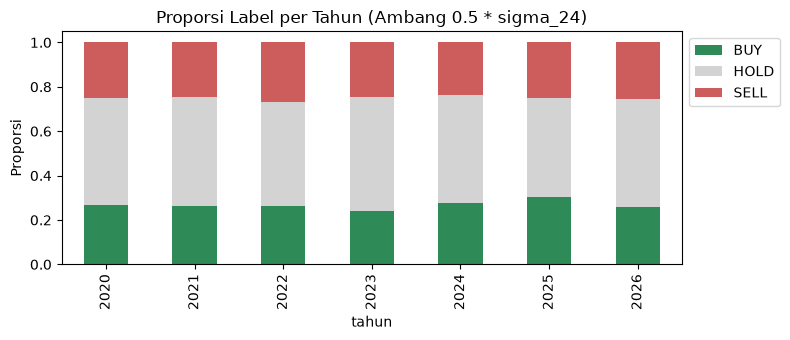

In [6]:
# Plot proporsi kelas per tahun untuk ambang utama 0.5
df_layak = df[df["target_layak"]].copy()
df_layak["tahun"] = df_layak["time"].dt.year

tahunan = df_layak.groupby("tahun")["label_0p5"].value_counts(normalize=True).unstack()[["BUY", "HOLD", "SELL"]]
ax = tahunan.plot.bar(stacked=True, figsize=(8, 3.5), color=["seagreen", "lightgray", "indianred"])
ax.set_ylabel("Proporsi")
ax.set_title("Proporsi Label per Tahun (Ambang 0.5 * sigma_24)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [7]:
kolom_label = [c for c in df.columns if c.startswith("label_")]
kolom_simpan = ["time", "decision_time", "target_end_time", "segment_id", "r", "sigma_24", "q", "target_layak"] + kolom_label

df[kolom_simpan].to_parquet(f"{DATA_DIR}/02_label.parquet", index=False)
print("Selesai! Tersimpan:", f"{DATA_DIR}/02_label.parquet", df[kolom_simpan].shape)

Selesai! Tersimpan: ../data/interim/phase4-p0/02_label.parquet (38799, 11)
